# 02 — Chunk Filings and Upsert to Qdrant

This notebook processes the downloaded 10-K filings into section-aware chunks and indexes them in Qdrant for retrieval.

**Pipeline:**
1. Load `filing_metadata.csv` from the previous notebook
2. Detect 10-K section boundaries (Item 1, 1A, 7, 7A, 8, 9A; every other Item is labelled "Other") and split into labelled sections
3. Chunk each section into 800-token chunks with 100-token overlap
4. Save all chunks to `data/processed/filing_chunks.parquet`
5. Embed chunks with `text-embedding-3-small` and upsert to the `sec_filings` Qdrant collection

**Expected output:** ~3,000–8,000 chunks total across all 15 filings.

In [1]:
import sys
sys.path.insert(0, '..')

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.config import PROCESSED_DIR, RAW_DIR
from src.chunking import process_all_filings, split_into_sections, chunk_section
from src.retrieval import get_qdrant_client, init_qdrant_collection, upsert_chunks

import os

metadata_path = os.path.join(PROCESSED_DIR, 'filing_metadata.csv')
metadata_df = pd.read_csv(metadata_path)
print(f"Loaded metadata for {len(metadata_df)} filings")
print(f"Available: {metadata_df['local_path'].notna().sum()} filings with local files")

Loaded metadata for 15 filings
Available: 15 filings with local files


## 2.1 — Section detection spot check

Before chunking everything, verify that section detection works correctly on one filing.

In [2]:
sample_row = metadata_df[(metadata_df['ticker'] == 'MSFT') & (metadata_df['year'] == 2023)].iloc[0]
with open(sample_row['local_path'], 'r', encoding='utf-8') as f:
    sample_text = f.read()

sections = split_into_sections(sample_text)
print(f"MSFT 2023: detected {len(sections)} sections")
for s in sections:
    words = len(s['text'].split())
    print(f"  {s['section_name']:30s} {words:,} words")

MSFT 2023: detected 9 sections
  Preamble                       2,744 words
  Business                       10,750 words
  Risk Factors                   10,149 words
  Other                          582 words
  MD&A                           8,414 words
  Market Risk                    525 words
  Financial Statements           16,720 words
  Controls                       1,422 words
  Other                          1,957 words


## 2.2 — Process and chunk all filings

In [3]:
chunks_path = os.path.join(PROCESSED_DIR, 'filing_chunks.parquet')

if os.path.exists(chunks_path):
    print(f"Loading existing chunks from {chunks_path}")
    chunks_df = pd.read_parquet(chunks_path)
else:
    print("Chunking all filings...")
    chunks_df = process_all_filings(metadata_df, raw_dir=RAW_DIR)

print(f"\nTotal chunks: {len(chunks_df):,}")
print(f"Columns: {list(chunks_df.columns)}")
chunks_df.head(3)

Loading existing chunks from /Users/xieweixun/Desktop/projects/sec-rag-failure-modes/notebooks/../src/../data/processed/filing_chunks.parquet



Total chunks: 2,916
Columns: ['chunk_id', 'ticker', 'company', 'year', 'filing_type', 'section', 'text', 'token_count']


,chunk_id,ticker,company,year,filing_type,section,text,token_count
0,AAPL_2022_preamble_0000,AAPL,Apple Inc.,2022,10-K,Preamble,aapl-20220924\nfalse\n2022\nFY\n0000320193\nP1...,800
1,AAPL_2022_preamble_0001,AAPL,Apple Inc.,2022,10-K,Preamble,Member\n2020-09-27\n2021-09-25\n0000320193\nus...,800
2,AAPL_2022_preamble_0002,AAPL,Apple Inc.,2022,10-K,Preamble,us-gaap:RetainedEarningsMember\n2022-09-24\n00...,800


## 2.3 — Chunk statistics by company and section

In [4]:
print("Chunks by company:")
print(chunks_df.groupby('ticker')['chunk_id'].count().sort_values(ascending=False))

print("\nChunks by section:")
print(chunks_df.groupby('section')['chunk_id'].count().sort_values(ascending=False))

print("\nAverage token count per chunk:")
print(chunks_df.groupby('section')['token_count'].mean().round(1).sort_values(ascending=False))

Chunks by company:
ticker
JPM     1543
TSLA     426
MSFT     386
NVDA     327
AAPL     234
Name: chunk_id, dtype: int64

Chunks by section:
section
Other                   1282
Preamble                 575
Risk Factors             343
Financial Statements     336
Business                 187
MD&A                     147
Controls                  28
Market Risk               18
Name: chunk_id, dtype: int64

Average token count per chunk:
section
Other                   787.5
Financial Statements    787.4
Preamble                787.4
Risk Factors            781.9
Business                768.1
MD&A                    766.5
Controls                635.1
Market Risk             526.7
Name: token_count, dtype: float64


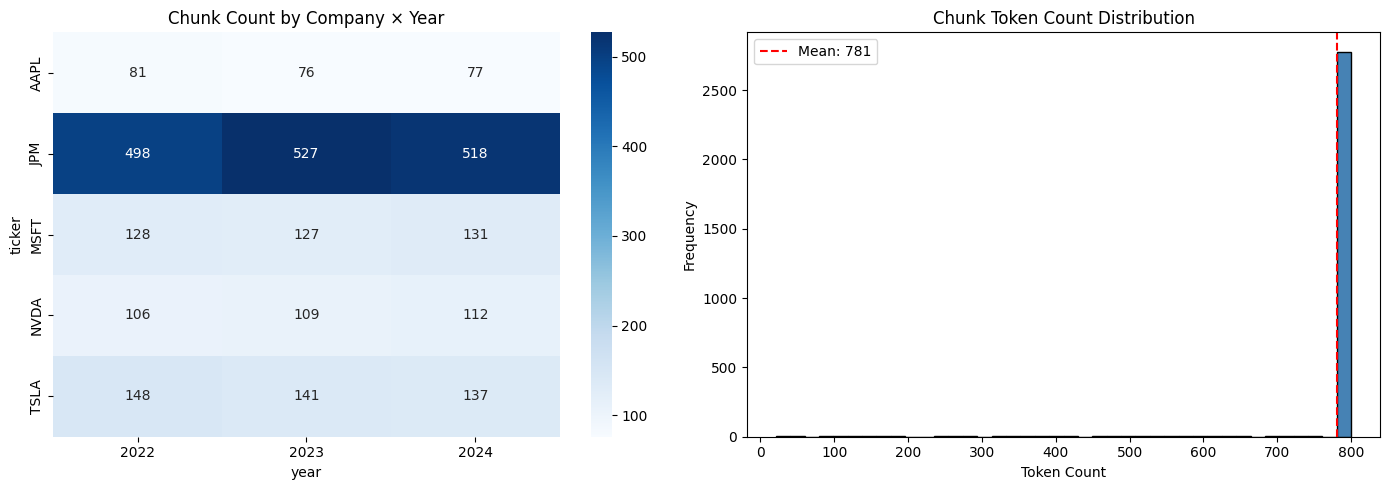

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Chunks by company × year heatmap
pivot = chunks_df.groupby(['ticker', 'year'])['chunk_id'].count().reset_index()
pivot = pivot.pivot(index='ticker', columns='year', values='chunk_id')
sns.heatmap(pivot, annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title('Chunk Count by Company × Year')

# Token count distribution
axes[1].hist(chunks_df['token_count'], bins=40, edgecolor='black', color='steelblue')
axes[1].axvline(chunks_df['token_count'].mean(), color='red', linestyle='--', label=f"Mean: {chunks_df['token_count'].mean():.0f}")
axes[1].set_xlabel('Token Count')
axes[1].set_ylabel('Frequency')
axes[1].set_title('Chunk Token Count Distribution')
axes[1].legend()

plt.tight_layout()
plt.savefig('../figures/chunk_stats.png', dpi=150, bbox_inches='tight')
plt.show()

## 2.4 — Initialize Qdrant and upsert chunks

In [6]:
client = get_qdrant_client()
init_qdrant_collection(client, recreate=True)  # drop stale points from any previous chunking

# Check current collection size
from src.config import QDRANT_COLLECTION
collection_info = client.get_collection(QDRANT_COLLECTION)
print(f"Collection '{QDRANT_COLLECTION}'")
print(f"  Points count:    {collection_info.points_count}")

Dropped collection: sec_filings
Created collection: sec_filings
Collection 'sec_filings'
  Points count:    0


/Users/xieweixun/Desktop/projects/sec-rag-failure-modes/notebooks/../src/retrieval.py:73: UserWarning: Payload indexes have no effect in the local Qdrant. Please use server Qdrant if you need payload indexes.
  client.create_payload_index(


In [7]:
# Upsert all chunks. This will re-embed and overwrite if run again.
# Estimated cost: ~$0.02 for 6,000 chunks at text-embedding-3-small pricing
upsert_chunks(client, chunks_df)

# Verify final count
collection_info = client.get_collection(QDRANT_COLLECTION)
print(f"\nFinal collection size: {collection_info.points_count} points")

Embedding 2916 chunks...


Upserting 2916 points to Qdrant...


Upserting batches:   0%|          | 0/30 [00:00<?, ?it/s]

Upserting batches:   3%|▎         | 1/30 [00:00<00:05,  5.51it/s]

Upserting batches:   7%|▋         | 2/30 [00:00<00:04,  5.87it/s]

...

Upserting batches:  90%|█████████ | 27/30 [00:04<00:00,  6.65it/s]

Upserting batches:  93%|█████████▎| 28/30 [00:04<00:00,  6.79it/s]

Upserting batches:  97%|█████████▋| 29/30 [00:04<00:00,  6.76it/s]

Upserting batches: 100%|██████████| 30/30 [00:04<00:00,  6.79it/s]

Upsert complete.

Final collection size: 2916 points


## 2.5 — Quick retrieval sanity check

In [8]:
from src.retrieval import vanilla_retrieval, metadata_filtered_retrieval

test_query = "NVIDIA data center revenue growth"
results = vanilla_retrieval(client, test_query, top_k=5)

print(f"Query: '{test_query}'")
print(f"Top {len(results)} results:\n")
for r in results:
    print(f"  {r['ticker']} {r['year']} | {r['section']} | score={r['score']:.4f}")
    print(f"  {r['text'][:200]}...")
    print()

Query: 'NVIDIA data center revenue growth'
Top 5 results:

  NVDA 2024 | MD&A | score=0.7055
  $
4,368
Up 581%
Net income per diluted share
$
11.93
$
1.74
Up 586%
We specialize in markets where our computing platforms can provide tremendous acceleration for applications. These platforms incorpo...

  NVDA 2023 | MD&A | score=0.6792
   55%
We specialize in markets where our computing platforms can provide tremendous acceleration for applications. These platforms incorporate processors, interconnects, software, algorithms, systems, ...

  NVDA 2022 | MD&A | score=0.6726
  914
$
16,675
Up 61%
Gross margin
64.9
%
62.3
%
Up 260 bps
Operating expenses
$
7,434
$
5,864
Up 27%
Income from operations
$
10,041
$
4,532
Up 122%
Net income
$
9,752
$
4,332
Up 125%
Net income per di...

  NVDA 2023 | MD&A | score=0.6642
   of fiscal year 2023, it is estimated this change will increase our fiscal year 2024 operating income by $133 million as a result of the reduction in depreciation expense.
Results of